# **7. Evaluación del recomendador**

### **7.1 Preparación del entorno de evaluación**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import time
from scipy.stats import pearsonr, spearmanr

from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances, pairwise_distances

In [2]:
# Información descriptiva de las canciones
df = pd.read_csv('../data/spotify-tracks-dataset-clean.csv')

df['genres_set'] = df['track_genre'].apply(
    lambda x: set(x.split(';'))
)

# Características musicales estandarizadas
X_audio_scaled = pd.read_csv('../data/spotify-audio-features-scaled.csv', index_col = 0)

In [3]:
# Verificar las columnas disponibles
print('Columnas de df:')
print(df.columns.tolist())

print('\nColumnas de X_audio_scaled:')
print(X_audio_scaled.columns.tolist())

# Verificar las dimensiones
print('\nDimensiones:')
print(f'df: {df.shape}')
print(f'X_audio_scaled: {X_audio_scaled.shape}')

# Verificar los índices
print('\n¿Tienen los mismos índices?', df.index.equals(X_audio_scaled.index))

Columnas de df:
['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre', 'genres_set']

Columnas de X_audio_scaled:
['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

Dimensiones:
df: (89578, 21)
X_audio_scaled: (89578, 9)

¿Tienen los mismos índices? True


In [4]:
# Inspeccionar los géneros musicales

print('Tipo de dato de genres_set:')
print(type(df['genres_set'].iloc[0]))

print('\nEjemplos de géneros:')
print(df['genres_set'].sample(5, random_state = 123))

Tipo de dato de genres_set:
<class 'set'>

Ejemplos de géneros:
88298    {punk, punk-rock}
80586         {house, edm}
70897           {trip-hop}
56199              {r-n-b}
62191         {show-tunes}
Name: genres_set, dtype: object


### **7.2 Selección de canciones de referencia**

In [5]:
# Definir los perfiles que queremos explorar

criterios = [
    ('Popularidad baja', df[df['popularity'] > 0], 'popularity', True),

    ('Popularidad alta', df, 'popularity', False),

    ('Energía baja', df, 'energy', True),

    ('Energía alta', df, 'energy', False),

    ('Acousticness baja', df, 'acousticness', True),

    ('Acousticness alta', df, 'acousticness', False),

    ('Instrumentalness baja', df, 'instrumentalness', True),

    ('Instrumentalness alta', df, 'instrumentalness', False)
]

# Obtener tres canciones por perfil

candidatas_referencia = []
for nombre, datos, variable, ascendente in criterios:

    seleccion = datos.sort_values(variable, ascending = ascendente).head(3).copy()
    seleccion.insert(0, 'criterio', nombre)

    candidatas_referencia.append(seleccion)

# Unificar los resultados

candidatas_referencia = pd.concat(candidatas_referencia)

# Preparar una tabla para inspeccionar las canciones

tabla_candidatas = candidatas_referencia[
    [
        'criterio',
        'track_name',
        'artists',
        'genres_set',
        'popularity',
        'energy',
        'acousticness',
        'instrumentalness'
    ]
].copy()

tabla_candidatas['genres_set'] = (
    tabla_candidatas['genres_set']
    .apply(lambda x: ', '.join(sorted(x)))
)

display(tabla_candidatas)

,criterio,track_name,artists,genres_set,popularity,energy,acousticness,instrumentalness
86577,Popularidad baja,No War,Âme,"minimal-techno, techno",1,0.68400,0.02130,0.854000
78328,Popularidad baja,I Wish,Joel Corry;Mabel,"dance, edm, house",1,0.85600,0.08960,0.000000
78367,Popularidad baja,Show Me The Wine,Vybz Kartel,"dancehall, j-dance, reggae",1,0.89600,0.06070,0.000000
77840,Popularidad alta,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,"dance, pop",100,0.47200,0.01300,0.000005
34894,Popularidad alta,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,hip-hop,99,0.78200,0.01250,0.033000
85881,Popularidad alta,La Bachata,Manuel Turizo,"latin, latino, reggae, reggaeton",98,0.67900,0.58300,0.000002
39132,Energía baja,Lima,Ali Phi,iranian,0,0.00002,0.99400,0.935000
27276,Energía baja,Vaggvisa för flyktbenägna,Håkan Hellström,goth,25,0.00002,0.56600,0.086900
22182,Energía baja,God Called In Sick Today,AFI,emo,33,0.00002,0.00786,0.002150
38365,Energía alta,Impulso Biomecanico,Amduscia,industrial,25,1.00000,0.13100,0.029500


In [6]:
# Canciones seleccionadas para la evaluación

indices_referencia = [
    77840,  # Unholy; Popularidad elevada y música pop
    86577,  # No War; Popularidad baja y música electrónica
    39132,  # Lima; Energía extremadamente baja
    38365,  # Impulso Biomecanico; Energía extremadamente alta
    28293,  # Copious Head Carnage; Baja acousticness y alta instrumentalidad
    77661,  # Carnaval, Op. 9: No. 2, Pierrot; Alta acousticness e instrumentalidad
    81,     # I'm Yours; Perfil acústico y baja instrumentalidad
    64319   # Fan Whir; Instrumentalidad máxima y sonido ambiental
]

# Crear tabla de referencias

referencias = df.loc[indices_referencia, [
    'track_name',
    'artists',
    'genres_set',
    'popularity',
    'energy',
    'acousticness',
    'instrumentalness'
]].copy()

display(referencias)

,track_name,artists,genres_set,popularity,energy,acousticness,instrumentalness
77840,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,"{dance, pop}",100,0.47200,0.0130,0.000005
86577,No War,Âme,"{techno, minimal-techno}",1,0.68400,0.0213,0.854000
39132,Lima,Ali Phi,{iranian},0,0.00002,0.9940,0.935000
38365,Impulso Biomecanico,Amduscia,{industrial},25,1.00000,0.1310,0.029500
28293,Copious Head Carnage,Regurgitate,{grindcore},11,0.99100,0.0000,0.923000
77661,"Carnaval, Op. 9: No. 2, Pierrot (Live in Japan...",Robert Schumann;Pavel Nersessian,"{classical, german}",0,0.02860,0.9960,0.917000
81,I'm Yours,Jason Mraz,{acoustic},60,0.43000,0.5650,0.000000
64319,Fan Whir,White Noise for Babies;Natural White Noise for...,{sleep},33,0.06080,0.8400,1.000000


In [7]:
# Evaluar la cantidad de candidatas disponibles por referencia

resultados_candidatas = []

for indice in indices_referencia:

    # Obtener géneros de la referencia
    generos_referencia = df.loc[indice, 'genres_set']

    # Identificar canciones que comparten al menos un género
    mascara = df['genres_set'].apply(
        lambda generos: bool(generos & generos_referencia)
    )

    candidatas = df.loc[mascara].drop(index = indice)

    # Eliminar repeticiones por título y artista
    candidatas_unicas = candidatas.drop_duplicates(subset = ['track_name', 'artists'])

    resultados_candidatas.append({
        'indice': indice,
        'cancion': df.loc[indice, 'track_name'],
        'generos_referencia': ', '.join(
            sorted(generos_referencia)
        ),
        'generos_compartidos': len(generos_referencia),
        'candidatas_iniciales': len(candidatas),
        'candidatas_unicas': len(candidatas_unicas)
    })

tabla_disponibilidad = pd.DataFrame(resultados_candidatas)

display(tabla_disponibilidad)

,indice,cancion,generos_referencia,generos_compartidos,candidatas_iniciales,candidatas_unicas
0,77840,Unholy (feat. Kim Petras),"dance, pop",2,1816,1174
1,86577,No War,"minimal-techno, techno",2,1673,1593
2,39132,Lima,iranian,1,983,953
3,38365,Impulso Biomecanico,industrial,1,999,927
4,28293,Copious Head Carnage,grindcore,1,997,977
5,77661,"Carnaval, Op. 9: No. 2, Pierrot (Live in Japan...","classical, german",2,1772,1509
6,81,I'm Yours,acoustic,1,999,941
7,64319,Fan Whir,sleep,1,861,821


### **7.2.1 Recomendaciones para las canciones de referencia**

In [8]:
def recomendar_canciones(indice, n_recomendaciones = 10):
    
    # Validar el índice de referencia
    if indice not in df.index:
        raise ValueError('El índice indicado no existe en el conjunto de datos.')

    # Validar el número de recomendaciones
    if not isinstance(n_recomendaciones, int) or isinstance(n_recomendaciones, bool):
        raise TypeError('El número de recomendaciones debe ser un entero.')

    if n_recomendaciones <= 0:
        raise ValueError('El número de recomendaciones debe ser positivo.')
    
    # Obtener los géneros de la canción de referencia
    generos_referencia = df.loc[indice, 'genres_set']

    # Filtrar canciones que compartan al menos un género
    mascara_genero = df['genres_set'].apply(
        lambda generos: bool(generos_referencia & generos)
    )

    # Excluir la canción de referencia
    mascara_genero.loc[indice] = False
    candidatas = df.loc[mascara_genero].copy()
    
    # Obtener las características acústicas
    caracteristicas_referencia = X_audio_scaled.loc[[indice]]
    caracteristicas_candidatas = X_audio_scaled.loc[candidatas.index]

    # Calcular las distancias euclidianas
    distancias = euclidean_distances(caracteristicas_referencia, caracteristicas_candidatas).flatten()
    distancias = pd.Series(distancias, index = candidatas.index)

    # Incorporar las distancias y eliminar canciones repetidas
    candidatas_unicas = (
        candidatas
        .assign(distancia_euclidiana = distancias)
        .sort_values(by = 'distancia_euclidiana', ascending = True)
        .drop_duplicates(subset = ['track_name', 'artists'], keep = 'first')
    )
    
    # Seleccionar las 100 canciones más cercanas
    candidatas_ordenadas = candidatas_unicas.sort_values(by = 'distancia_euclidiana', ascending = True)
    df_candidatas = candidatas_ordenadas.head(100).copy()

    indices_seleccionados = df_candidatas.index
    X_candidatas = X_audio_scaled.loc[indices_seleccionados]

    # Calcular la similitud del coseno
    similitudes = cosine_similarity(caracteristicas_referencia, X_candidatas).flatten()
    similitudes = pd.Series(similitudes, index = X_candidatas.index)

    # Ordenar por similitud del coseno
    similitudes_ordenadas = similitudes.sort_values(ascending = False)
    
    # Construir la tabla de recomendaciones
    recomendaciones = df_candidatas.loc[
        similitudes_ordenadas.index, ['track_name', 'artists', 'track_genre', 'album_name']
    ].copy()

    recomendaciones['distancia_euclidiana'] = (
        df_candidatas.loc[recomendaciones.index, 'distancia_euclidiana']
    )
    recomendaciones['similitud_coseno'] = similitudes_ordenadas

    # Devolver las recomendaciones solicitadas
    return recomendaciones.head(n_recomendaciones)

In [9]:
# Generar recomendaciones para todas las referencias

recomendaciones_hibridas = {}

for indice in indices_referencia:

    recomendaciones = recomendar_canciones(indice, n_recomendaciones = 10)

    recomendaciones_hibridas[indice] = recomendaciones

print("Evaluación de referencias completada.")
print("Referencias procesadas:", len(recomendaciones_hibridas))

Evaluación de referencias completada.
Referencias procesadas: 8


In [10]:
# Mostrar las recomendaciones de cada referencia

for indice, recomendaciones in recomendaciones_hibridas.items():

    cancion = df.loc[indice, 'track_name']
    artista = df.loc[indice, 'artists']

    print(f'Referencia: {cancion} — {artista}')
    display(recomendaciones)

Referencia: Unholy (feat. Kim Petras) — Sam Smith;Kim Petras


,track_name,artists,track_genre,album_name,distancia_euclidiana,similitud_coseno
78060,Shower,Becky G,dance;latin;reggae;reggaeton,Shower,0.721647,0.930515
77981,I Don’t Wanna Live Forever (Fifty Shades Darker),ZAYN;Taylor Swift,dance;pop,reputation Stadium Tour Surprise Song Playlist,1.016902,0.880780
78181,Scared to Be Lonely,Martin Garrix;Dua Lipa,dance;edm;house;progressive-house,Scared to Be Lonely,0.907557,0.865587
14413,Dark Horse,Katy Perry;Juicy J,dance,Halloween 2022,0.979889,0.841791
53394,Falling,Trevor Daniel,pop,Nicotine,1.188391,0.823348
87694,The Humma Song,A.R. Rahman;Badshah;Tanishk Bagchi;Shashaa Tir...,pop;pop-film,OK Jaanu (Original Motion Picture Soundtrack),1.080201,0.810927
78186,Or Nah - Remix,Ty Dolla $ign;The Weeknd;Wiz Khalifa;DJ Mustard,dance;hip-hop;soul,Good Vibes,1.340376,0.809514
14678,Cool for the Summer - Sped Up (Nightcore),Demi Lovato;Speed Radio,dance,Best Viral Tunes,1.073507,0.805708
78158,Fr Fr,Wiz Khalifa;Lil Skies,dance;hip-hop,Rap Party,1.626549,0.788049
81035,idfc,blackbear,electro;pop,dead,1.170133,0.783261


Referencia: No War — Âme


,track_name,artists,track_genre,album_name,distancia_euclidiana,similitud_coseno
47756,ENCHANTé - Original Version,Laurent Garnier,minimal-techno,La Home Box,0.349437,0.991155
86580,Bright,Fritz Kalkbrenner;Ben Böhmer,minimal-techno;techno,True Colours,0.386102,0.989171
86654,Up All Night - Radio Edit,Agoria,minimal-techno;techno,Up All Night,0.531795,0.982644
47741,Immunity,Nils Hoffmann,minimal-techno,A Radiant Sign,0.523152,0.980902
69646,All I Want (feat. Goatchy),Tube & Berger;Goatchy,techno,All I Want (feat. Goatchy),0.531562,0.978911
69749,Sinematic,Zimmz,techno,Sinematic,0.592497,0.976697
86687,King Curtis - Edit,Fritz Kalkbrenner,minimal-techno;techno,King Curtis,0.594527,0.976071
47675,Ignition,Einmusik,minimal-techno,Ignition,0.802552,0.974214
69498,Aura,Avoure,techno,Armada Deep - Ibiza 2019,0.693097,0.971761
69704,Console,Zimmz,techno,"A-Sides, Vol. 8",0.700181,0.971519


Referencia: Lima — Ali Phi


,track_name,artists,track_genre,album_name,distancia_euclidiana,similitud_coseno
38941,Spellbound,Alphaxone,iranian,Chronosphere,0.762871,0.991096
39505,Limitation,Spuntic,iranian,Broadcast,0.965028,0.988006
39189,For I Wasn't Steel,Pouya Pour-Amin,iranian,Prison Episodes,0.905665,0.987415
39642,I Know,Asef Akbari,iranian,Wet And Warm,1.516353,0.985173
39106,Departure,Alphaxone,iranian,Echoes from Outer Silence,1.253256,0.985054
38959,Kani (Night),Porya Hatami,iranian,Kani,1.170335,0.984586
39418,"Persian Gardens, Op. 111 : Episode V",Alireza Mashayekhi;Farimah Ghavamsadri;Nationa...,iranian,Persian Gardens (Piece for Piano and Orchestra),1.323443,0.982880
39113,Mysterious,Alphaxone,iranian,Tomb of Empires,1.111239,0.982859
39100,Echosphere,Alphaxone,iranian,Edge of Solitude,1.282060,0.980684
38966,Awakening,Alphaxone,iranian,Living in the Grayland,1.280113,0.980525


... (6 outputs left out)

Referencia: I'm Yours — Jason Mraz


,track_name,artists,track_genre,album_name,distancia_euclidiana,similitud_coseno
10,I'm Yours,Jason Mraz,acoustic,We Sing. We Dance. We Steal Things.,0.113974,0.998727
798,Cried Like A Baby,Rory Block,acoustic,Cried Like A Baby,1.042040,0.934070
217,Stand Your Ground,Joshua Hyslop,acoustic,Echos,0.974135,0.906852
631,Magic,Gabrielle Aplin,acoustic,Dear Happy,1.032977,0.902292
73299,Winter Wonderland,Jason Mraz,acoustic;rock,Christmas Music - Holiday Hits,1.006012,0.899411
73377,Bulletproof,Ben Woodward,acoustic;chill,Bulletproof,0.934979,0.897183
238,2002 - Acoustic,Amber Leigh Irish,acoustic,Simply Acoustic,1.372003,0.867778
553,Your Song,Suy Galvez,acoustic,Bossa Best,1.140662,0.863729
177,Marigold,Phillip LaRue,acoustic,The Meaning,1.177460,0.855769
401,Peaches - Acoustic,Adam Christopher,acoustic,Peaches (Acoustic),1.443913,0.848711


Referencia: Fan Whir — White Noise for Babies;Natural White Noise for Babies;White Noise Baby Sleep;White Noise Nature Sounds Baby Sleep


,track_name,artists,track_genre,album_name,distancia_euclidiana,similitud_coseno
64189,Fan Whir,Soothing White Noise for Relaxation;Sleepiciou...,sleep,Sea & Fan Breeze Calming White Noises,8.429370e-08,1.000000
63697,Beautiful Imagination,Little Circuits,sleep,Beautiful Imagination,3.877523e-01,0.998630
64542,Waves From The Ocean,Ocean Waves For Sleep,sleep,Waves Sounds,4.968053e-01,0.997691
64309,Touha,Marie Protivová,sleep,Touha,5.585748e-01,0.997149
64432,Eternal Glow,Soothe My Soul,sleep,Eternal Glow,9.144435e-01,0.996531
64021,Anatomy of Change,Oto Roth,sleep,Anatomy of Change,7.147080e-01,0.995795
64476,Ulayaw,Elise Ryen,sleep,Ulayaw,6.814564e-01,0.995421
64299,Departure,Soothe My Soul,sleep,Departure,8.681538e-01,0.995287
64052,Reappearance,Spacetactular,sleep,Reappearance,7.991552e-01,0.994963
64302,Bylgjur,Einingu,sleep,Bylgjur,8.464068e-01,0.994541


### **7.2.2 Coincidencias entre las canciones de referencia y las recomendaciones**

In [11]:
# Revisar la identidad de las canciones de referencia
for indice in indices_referencia:

    referencia = df.loc[indice]

    # Buscar coincidencias exactas de título y artista
    coincidencias = df[
        (df['track_name'] == referencia['track_name']) &
        (df['artists'] == referencia['artists'])
    ]

    if len(coincidencias) > 1:
        print(f'\nÍndice: {indice}')
        print('Canción:', referencia['track_name'])
        print('Artista:', referencia['artists'])
        print('track_id:', referencia['track_id'])
        print('Registros con mismo título y artista:', len(coincidencias))
        display(
            coincidencias[
                ['track_id', 'track_name', 'artists', 'album_name', 'track_genre']
            ]
        )


Índice: 81
Canción: I'm Yours
Artista: Jason Mraz
track_id: 03yc0G2OoH1Eeyu7Piy8fK
Registros con mismo título y artista: 3


,track_id,track_name,artists,album_name,track_genre
10,3S0OXQeoh0w6AY8WQVckRW,I'm Yours,Jason Mraz,We Sing. We Dance. We Steal Things.,acoustic
81,03yc0G2OoH1Eeyu7Piy8fK,I'm Yours,Jason Mraz,I'm Yours,acoustic
73284,1EzrEOXmMH3G43AXT1y7pA,I'm Yours,Jason Mraz,We Sing. We Dance. We Steal Things.,acoustic;rock


### **7.2.3 Reformulación de la función**

In [12]:
def recomendar_canciones(indice, n_recomendaciones = 10):
    
    # Validar el índice de referencia
    if indice not in df.index:
        raise ValueError('El índice indicado no existe en el conjunto de datos.')

    # Validar el número de recomendaciones
    if not isinstance(n_recomendaciones, int) or isinstance(n_recomendaciones, bool):
        raise TypeError('El número de recomendaciones debe ser un entero.')

    if n_recomendaciones <= 0:
        raise ValueError('El número de recomendaciones debe ser positivo.')
    
    # Obtener los géneros de la canción de referencia
    generos_referencia = df.loc[indice, 'genres_set']

    # Filtrar canciones que compartan al menos un género
    mascara_genero = df['genres_set'].apply(
        lambda generos: bool(generos_referencia & generos)
    )

    # Excluir la canción de referencia y sus registros equivalentes
    referencia = df.loc[indice]

    misma_cancion = (
        (df['track_name'] == referencia['track_name']) & (df['artists'] == referencia['artists'])
    )

    mascara_genero = mascara_genero & ~misma_cancion
    candidatas = df.loc[mascara_genero].copy()
    
    # Obtener las características acústicas
    caracteristicas_referencia = X_audio_scaled.loc[[indice]]
    caracteristicas_candidatas = X_audio_scaled.loc[candidatas.index]

    # Calcular las distancias euclidianas
    distancias = euclidean_distances(caracteristicas_referencia, caracteristicas_candidatas).flatten()
    distancias = pd.Series(distancias, index = candidatas.index)

    # Incorporar las distancias y eliminar canciones repetidas
    candidatas_unicas = (
        candidatas
        .assign(distancia_euclidiana = distancias)
        .sort_values(by = 'distancia_euclidiana', ascending = True)
        .drop_duplicates(subset = ['track_name', 'artists'], keep = 'first')
    )
    
    # Seleccionar las 100 canciones más cercanas
    candidatas_ordenadas = candidatas_unicas.sort_values(by = 'distancia_euclidiana', ascending = True)
    df_candidatas = candidatas_ordenadas.head(100).copy()

    indices_seleccionados = df_candidatas.index
    X_candidatas = X_audio_scaled.loc[indices_seleccionados]

    # Calcular la similitud del coseno
    similitudes = cosine_similarity(caracteristicas_referencia, X_candidatas).flatten()
    similitudes = pd.Series(similitudes, index = X_candidatas.index)

    # Ordenar por similitud del coseno
    similitudes_ordenadas = similitudes.sort_values(ascending = False)
    
    # Construir la tabla de recomendaciones
    recomendaciones = df_candidatas.loc[
        similitudes_ordenadas.index, ['track_name', 'artists', 'track_genre', 'album_name']
    ].copy()

    recomendaciones['distancia_euclidiana'] = (
        df_candidatas.loc[recomendaciones.index, 'distancia_euclidiana']
    )
    recomendaciones['similitud_coseno'] = similitudes_ordenadas

    # Devolver las recomendaciones solicitadas
    return recomendaciones.head(n_recomendaciones)

### **7.3 Evaluación de la diversidad de las recomendaciones**

In [13]:
# Calcular la diversidad acústica de cada conjunto
diversidad_acustica = []

for indice, recomendaciones in recomendaciones_hibridas.items():

    # Recuperar los vectores acústicos de las canciones recomendadas
    vectores = X_audio_scaled.loc[recomendaciones.index]

    # Calcular las distancias euclidianas entre todos los pares
    matriz_distancias = pairwise_distances(vectores, metric = 'euclidean')

    # Obtener únicamente las distancias entre pares distintos
    indices_pares = np.triu_indices(len(vectores), k = 1)
    distancias_pares = matriz_distancias[indices_pares]

    # Calcular la distancia promedio
    distancia_promedio = distancias_pares.mean()

    diversidad_acustica.append({
        'indice_referencia': indice,
        'cancion_referencia': df.loc[indice, 'track_name'],
        'distancia_acustica_promedio': distancia_promedio
    })

# Construir tabla de resultados
tabla_diversidad_acustica = pd.DataFrame(diversidad_acustica)

display(tabla_diversidad_acustica.round(4).sort_values(by = 'distancia_acustica_promedio'))

,indice_referencia,cancion_referencia,distancia_acustica_promedio
1,86577,No War,0.6970
4,28293,Copious Head Carnage,0.7440
7,64319,Fan Whir,0.7460
2,39132,Lima,0.9418
3,38365,Impulso Biomecanico,0.9951
5,77661,"Carnaval, Op. 9: No. 2, Pierrot (Live in Japan...",1.1201
6,81,I'm Yours,1.3535
0,77840,Unholy (feat. Kim Petras),1.5317


### **7.4 Diversidad de artistas únicos**

In [14]:
# Calcular el número de artistas únicos por referencia
diversidad_artistas = []

for indice, recomendaciones in recomendaciones_hibridas.items():

    # Separar los artistas cuando hay colaboraciones
    artistas = (recomendaciones['artists'].str.split(';').explode().str.strip())

    # Contar los artistas diferentes
    numero_artistas = artistas.nunique()

    diversidad_artistas.append({
        'indice_referencia': indice,
        'cancion_referencia': df.loc[indice, 'track_name'],
        'artistas_unicos': numero_artistas
    })

# Construir la tabla de resultados
tabla_diversidad_artistas = pd.DataFrame(diversidad_artistas)

display(tabla_diversidad_artistas.sort_values(by = 'artistas_unicos', ascending = False))


,indice_referencia,cancion_referencia,artistas_unicos
0,77840,Unholy (feat. Kim Petras),21
7,64319,Fan Whir,12
5,77661,"Carnaval, Op. 9: No. 2, Pierrot (Live in Japan...",11
1,86577,No War,10
4,28293,Copious Head Carnage,10
2,39132,Lima,9
6,81,I'm Yours,9
3,38365,Impulso Biomecanico,8


In [15]:
# Calcular el número de recomendaciones de cada conjunto
tabla_diversidad_artistas['total_recomendaciones'] = [
    len(recomendaciones)
    for recomendaciones in recomendaciones_hibridas.values()
]

# Calcular artistas únicos por recomendación
tabla_diversidad_artistas['artistas_por_recomendacion'] = (
    tabla_diversidad_artistas['artistas_unicos'] / tabla_diversidad_artistas['total_recomendaciones']
)

display(
    tabla_diversidad_artistas.round(3)
)

,indice_referencia,cancion_referencia,artistas_unicos,total_recomendaciones,artistas_por_recomendacion
0,77840,Unholy (feat. Kim Petras),21,10,2.1
1,86577,No War,10,10,1.0
2,39132,Lima,9,10,0.9
3,38365,Impulso Biomecanico,8,10,0.8
4,28293,Copious Head Carnage,10,10,1.0
5,77661,"Carnaval, Op. 9: No. 2, Pierrot (Live in Japan...",11,10,1.1
6,81,I'm Yours,9,10,0.9
7,64319,Fan Whir,12,10,1.2


### **7.5 Popularidad de las recomendaciones**

In [16]:
# Calcular estadísticas de popularidad por referencia
estadisticas_popularidad = []

for indice, recomendaciones in recomendaciones_hibridas.items():

    # Recuperar la popularidad de las canciones recomendadas
    popularidades = df.loc[recomendaciones.index, 'popularity']

    estadisticas_popularidad.append({
        'indice_referencia': indice,
        'cancion_referencia': df.loc[indice, 'track_name'],
        'popularidad_media': popularidades.mean(),
        'popularidad_mediana': popularidades.median(),
        'popularidad_minima': popularidades.min(),
        'popularidad_maxima': popularidades.max()
    })

# Construir la tabla de resultados
tabla_popularidad = pd.DataFrame(estadisticas_popularidad)

display(tabla_popularidad.round(2).sort_values(by = 'popularidad_media', ascending = False))

,indice_referencia,cancion_referencia,popularidad_media,popularidad_mediana,popularidad_minima,popularidad_maxima
7,64319,Fan Whir,56.3,59.5,32,71
0,77840,Unholy (feat. Kim Petras),46.4,72.0,0,81
6,81,I'm Yours,44.2,51.0,0,75
1,86577,No War,39.5,37.5,21,58
3,38365,Impulso Biomecanico,27.6,23.0,1,60
4,28293,Copious Head Carnage,13.2,13.0,11,17
5,77661,"Carnaval, Op. 9: No. 2, Pierrot (Live in Japan...",5.8,0.5,0,25
2,39132,Lima,5.7,6.0,0,15


### **7.5.1 Distribución de popularidad del catálogo**

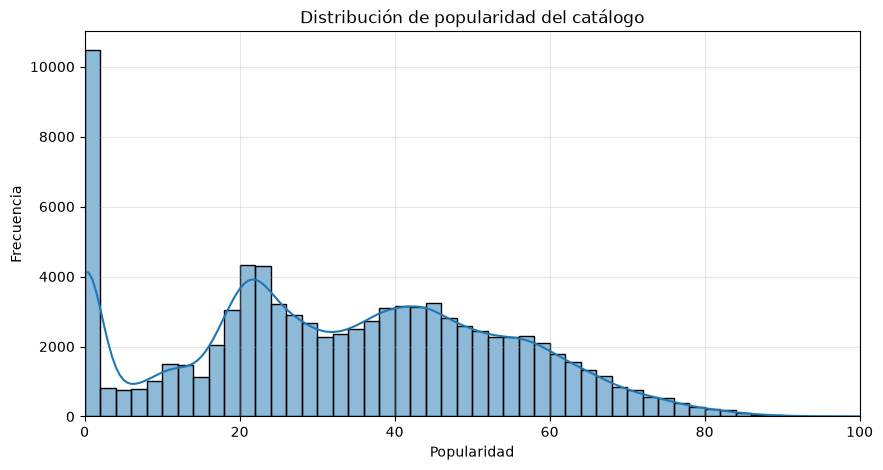

In [17]:
# Visualizar la distribución de popularidad del catálogo
plt.figure(figsize = (10, 5))

sns.histplot(data = df, x = 'popularity', bins = 50, kde = True)

plt.title('Distribución de popularidad del catálogo')
plt.xlabel('Popularidad')
plt.ylabel('Frecuencia')
plt.xlim(0, 100)
plt.grid(alpha = 0.3)

plt.show()

### **7.5.2 Distribución de popularidad de las recomendaciones**

In [18]:
# Seleccionar canciones con popularidad mayor que cero
popularidad_positiva = df.loc[df['popularity'] > 0, 'popularity']

# Calcular los percentiles 33 y 66
percentil_33 = popularidad_positiva.quantile(0.33)
percentil_66 = popularidad_positiva.quantile(0.66)

# Mostrar los resultados
print(f'Percentil 33: {percentil_33:.2f}')
print(f'Percentil 66: {percentil_66:.2f}')

Percentil 33: 26.00
Percentil 66: 45.00


In [19]:
# Definir las categorías de popularidad
distribucion_popularidad = []

for indice, recomendaciones in recomendaciones_hibridas.items():

    # Recuperar la popularidad de las recomendaciones
    popularidades = df.loc[recomendaciones.index, 'popularity']

    # Contar canciones en cada categoría
    sin_popularidad = (popularidades == 0).sum()
    popularidad_baja = popularidades.between(1, 26).sum()
    popularidad_media = popularidades.between(27, 45).sum()
    popularidad_alta = popularidades.between(46, 100).sum()

    distribucion_popularidad.append({
        'indice_referencia': indice,
        'cancion_referencia': df.loc[indice, 'track_name'],
        'sin_popularidad': sin_popularidad,
        'popularidad_baja': popularidad_baja,
        'popularidad_media': popularidad_media,
        'popularidad_alta': popularidad_alta
    })

# Construir la tabla de resultados
tabla_distribucion_popularidad = pd.DataFrame(distribucion_popularidad)

display(tabla_distribucion_popularidad)

,indice_referencia,cancion_referencia,sin_popularidad,popularidad_baja,popularidad_media,popularidad_alta
0,77840,Unholy (feat. Kim Petras),3,1,0,6
1,86577,No War,0,2,4,4
2,39132,Lima,4,6,0,0
3,38365,Impulso Biomecanico,0,8,0,2
4,28293,Copious Head Carnage,0,10,0,0
5,77661,"Carnaval, Op. 9: No. 2, Pierrot (Live in Japan...",5,5,0,0
6,81,I'm Yours,1,1,2,6
7,64319,Fan Whir,0,0,2,8


### **7.5.3 Distribución de las categorías de popularidad del catálogo**

In [20]:
# Clasificar todas las canciones del catálogo
popularidad_catalogo = df['popularity']

conteos_catalogo = {
    'sin_popularidad': (popularidad_catalogo == 0).sum(),
    'popularidad_baja': popularidad_catalogo.between(1, 26).sum(),
    'popularidad_media': popularidad_catalogo.between(27, 45).sum(),
    'popularidad_alta': popularidad_catalogo.between(46, 100).sum()
}

# Construir tabla de distribución
tabla_catalogo = pd.DataFrame({
    'categoria': conteos_catalogo.keys(),
    'canciones': conteos_catalogo.values()
})

# Calcular porcentajes respecto al catálogo completo
tabla_catalogo['porcentaje'] = (tabla_catalogo['canciones'] / len(df) * 100)

display(tabla_catalogo.round(2))

,categoria,canciones,porcentaje
0,sin_popularidad,9343,10.43
1,popularidad_baja,27029,30.17
2,popularidad_media,26600,29.69
3,popularidad_alta,26606,29.70


In [21]:
# Categorías que vamos a comparar
categorias = ['sin_popularidad', 'popularidad_baja', 'popularidad_media', 'popularidad_alta']

# Crear una copia de la tabla de recomendaciones
tabla_comparacion_popularidad = tabla_distribucion_popularidad[['indice_referencia', 'cancion_referencia']].copy()

# Obtener los porcentajes del catálogo
porcentajes_catalogo = tabla_catalogo.set_index('categoria')['porcentaje']

for categoria in categorias:

    # Porcentaje dentro de cada conjunto de recomendaciones
    porcentaje_recomendaciones = (
        tabla_distribucion_popularidad[categoria] /
        tabla_distribucion_popularidad[
            'sin_popularidad'
        ].mul(0).add(10)
    ) * 100

    # Diferencia respecto al catálogo
    diferencia = (porcentaje_recomendaciones - porcentajes_catalogo[categoria])

    tabla_comparacion_popularidad[f'diferencia_{categoria}'] = diferencia

display(tabla_comparacion_popularidad.round(2))


,indice_referencia,cancion_referencia,diferencia_sin_popularidad,diferencia_popularidad_baja,diferencia_popularidad_media,diferencia_popularidad_alta
0,77840,Unholy (feat. Kim Petras),19.57,-20.17,-29.69,30.3
1,86577,No War,-10.43,-10.17,10.31,10.3
2,39132,Lima,29.57,29.83,-29.69,-29.7
3,38365,Impulso Biomecanico,-10.43,49.83,-29.69,-9.7
4,28293,Copious Head Carnage,-10.43,69.83,-29.69,-29.7
5,77661,"Carnaval, Op. 9: No. 2, Pierrot (Live in Japan...",39.57,19.83,-29.69,-29.7
6,81,I'm Yours,-0.43,-20.17,-9.69,30.3
7,64319,Fan Whir,-10.43,-30.17,-9.69,50.3


### **7.6 Diversidad de géneros**

In [22]:
resumen_generos = {}

for indice, recomendaciones in recomendaciones_hibridas.items():

    # Recuperar los géneros de las canciones recomendadas
    generos = df.loc[recomendaciones.index, 'genres_set']

    # Descomponer los conjuntos de géneros
    generos_desglosados = generos.explode()

    # Contar las canciones asociadas a cada género
    frecuencia_generos = generos_desglosados.value_counts()

    # Guardar los resultados
    resumen_generos[indice] = {
        'generos_distintos': frecuencia_generos.size,
        'frecuencia_generos': frecuencia_generos
    }
    
tabla_diversidad_generos = pd.DataFrame({
    indice: {
        'generos_distintos': resultados['generos_distintos']
    }
    for indice, resultados in resumen_generos.items()
}).T

tabla_diversidad_generos

,generos_distintos
77840,12
86577,2
39132,1
38365,4
28293,1
77661,3
81,3
64319,1


In [23]:
for indice, resultados in resumen_generos.items():
    
    print(f'\nReferencia: {df.loc[indice, "track_name"]}')
    print(resultados['frecuencia_generos'])


Referencia: Unholy (feat. Kim Petras)
genres_set
dance                7
pop                  4
hip-hop              2
reggaeton            1
latin                1
reggae               1
house                1
progressive-house    1
edm                  1
pop-film             1
soul                 1
electro              1
Name: count, dtype: int64

Referencia: No War
genres_set
techno            7
minimal-techno    6
Name: count, dtype: int64

Referencia: Lima
genres_set
iranian    10
Name: count, dtype: int64

Referencia: Impulso Biomecanico
genres_set
industrial     10
alt-rock        1
metal           1
alternative     1
Name: count, dtype: int64

Referencia: Copious Head Carnage
genres_set
grindcore    10
Name: count, dtype: int64

Referencia: Carnaval, Op. 9: No. 2, Pierrot (Live in Japan, 2022)
genres_set
classical    10
german        3
ambient       1
Name: count, dtype: int64

Referencia: I'm Yours
genres_set
acoustic    10
rock         1
chill        1
Name: count, dtype: in

### **7.6.1 Entropía de Shannon**

In [24]:
resultados_entropia = {}

for indice, resultados in resumen_generos.items():

    # Recuperar las frecuencias de los géneros
    frecuencias = resultados['frecuencia_generos'].values

    # Calcular las proporciones
    proporciones = frecuencias / frecuencias.sum()

    # Número de géneros distintos
    G = len(frecuencias)

    # Entropía de Shannon
    H = -np.sum(proporciones * np.log(proporciones))

    # Entropía normalizada
    H_norm = H / np.log(G) if G > 1 else 0

    # Guardar resultados
    resultados_entropia[indice] = {
        'generos_distintos': G,
        'entropia': H,
        'entropia_normalizada': H_norm
    }

tabla_entropia = pd.DataFrame(resultados_entropia).T
tabla_entropia

,generos_distintos,entropia,entropia_normalizada
77840,12.0,2.156822,0.867969
86577,2.0,0.690186,0.995727
39132,1.0,-0.000000,0.000000
38365,4.0,0.793730,0.572555
28293,1.0,-0.000000,0.000000
77661,3.0,0.758937,0.690814
81,3.0,0.566086,0.515273
64319,1.0,-0.000000,0.000000


### **7.7 Eficiencia computacional**

In [25]:
tiempos_ejecucion = {}

for indice in indices_referencia:

    # Ejecución previa, no contabilizada
    recomendar_canciones(indice, n_recomendaciones = 10)

    mediciones = []
    # Cinco mediciones
    for _ in range(5):

        inicio = time.perf_counter()

        recomendaciones = recomendar_canciones(indice, n_recomendaciones = 10)

        fin = time.perf_counter()

        mediciones.append(fin - inicio)

    tiempos_ejecucion[indice] = {
        'tiempo_mediano': np.median(mediciones),
        'tiempo_minimo': np.min(mediciones),
        'tiempo_maximo': np.max(mediciones)
    }

tablas_tiempos = pd.DataFrame(tiempos_ejecucion).T
tablas_tiempos

,tiempo_mediano,tiempo_minimo,tiempo_maximo
77840,0.117189,0.090694,0.206108
86577,0.095764,0.090865,0.115708
39132,0.089148,0.086975,0.090466
38365,0.090859,0.090168,0.091570
28293,0.088690,0.087626,0.092100
77661,0.093661,0.091499,0.095561
81,0.088089,0.087451,0.092519
64319,0.087563,0.085905,0.091083


### **7.7.1 Registro de las cantidades de datos**

In [26]:
def recomendar_canciones(indice, n_recomendaciones = 10, return_diagnosticos = False):
    
    # Validar el índice de referencia
    if indice not in df.index:
        raise ValueError('El índice indicado no existe en el conjunto de datos.')
    
    # Tamaño del catálogo completo
    n_catalogo = len(df)

    # Validar el número de recomendaciones
    if not isinstance(n_recomendaciones, int) or isinstance(n_recomendaciones, bool):
        raise TypeError('El número de recomendaciones debe ser un entero.')

    if n_recomendaciones <= 0:
        raise ValueError('El número de recomendaciones debe ser positivo.')
    
    # Obtener los géneros de la canción de referencia
    generos_referencia = df.loc[indice, 'genres_set']

    # Filtrar canciones que compartan al menos un género
    mascara_genero = df['genres_set'].apply(
        lambda generos: bool(generos_referencia & generos)
    )
    
    # Canciones que comparten algún género
    n_genero = mascara_genero.sum()

    # Excluir la canción de referencia y sus registros equivalentes
    referencia = df.loc[indice]

    misma_cancion = (
        (df['track_name'] == referencia['track_name']) & (df['artists'] == referencia['artists'])
    )

    mascara_genero = mascara_genero & ~misma_cancion
    candidatas = df.loc[mascara_genero].copy()
    
    # Cantidad de candidatas
    n_candidatas = len(candidatas)
    
    # Obtener las características acústicas
    caracteristicas_referencia = X_audio_scaled.loc[[indice]]
    caracteristicas_candidatas = X_audio_scaled.loc[candidatas.index]

    # Calcular las distancias euclidianas
    distancias = euclidean_distances(caracteristicas_referencia, caracteristicas_candidatas).flatten()
    distancias = pd.Series(distancias, index = candidatas.index)

    # Incorporar las distancias y eliminar canciones repetidas
    candidatas_unicas = (
        candidatas
        .assign(distancia_euclidiana = distancias)
        .sort_values(by = 'distancia_euclidiana', ascending = True)
        .drop_duplicates(subset = ['track_name', 'artists'], keep = 'first')
    )
    
    # Candidatas sin duplicados
    n_unicas = len(candidatas_unicas)
    
    # Seleccionar las 100 canciones más cercanas
    candidatas_ordenadas = candidatas_unicas.sort_values(by = 'distancia_euclidiana', ascending = True)
    df_candidatas = candidatas_ordenadas.head(100).copy()
    
    # Candidatas finales para la similitud del coseno
    n_coseno = len(df_candidatas)

    indices_seleccionados = df_candidatas.index
    X_candidatas = X_audio_scaled.loc[indices_seleccionados]

    # Calcular la similitud del coseno
    similitudes = cosine_similarity(caracteristicas_referencia, X_candidatas).flatten()
    similitudes = pd.Series(similitudes, index = X_candidatas.index)

    # Ordenar por similitud del coseno
    similitudes_ordenadas = similitudes.sort_values(ascending = False)
    
    # Construir la tabla de recomendaciones
    recomendaciones = df_candidatas.loc[
        similitudes_ordenadas.index, ['track_name', 'artists', 'track_genre', 'album_name']
    ].copy()

    recomendaciones['distancia_euclidiana'] = (
        df_candidatas.loc[recomendaciones.index, 'distancia_euclidiana']
    )
    recomendaciones['similitud_coseno'] = similitudes_ordenadas

    # Devolver las recomendaciones solicitadas o el diagnóstico
    resultado = recomendaciones.head(n_recomendaciones)

    if return_diagnosticos:

        diagnosticos = {
            'canciones_catalogo': n_catalogo,
            'canciones_mismo_genero': n_genero,
            'candidatas_filtradas': n_candidatas,
            'candidatas_unicas': n_unicas,
            'candidatas_coseno': n_coseno,
            'recomendaciones': len(resultado)
        }

        return resultado, diagnosticos

    return resultado

In [27]:
recomendaciones, diagnosticos = recomendar_canciones(
    77840,
    n_recomendaciones = 10,
    return_diagnosticos = True
)

diagnosticos

{'canciones_catalogo': 89578,
 'canciones_mismo_genero': np.int64(1817),
 'candidatas_filtradas': 1816,
 'candidatas_unicas': 1174,
 'candidatas_coseno': 100,
 'recomendaciones': 10}

In [28]:
diagnosticos_hibrido = {}

for indice in indices_referencia:

    _, diagnosticos = recomendar_canciones(
        indice,
        n_recomendaciones = 10,
        return_diagnosticos = True
    )

    diagnosticos_hibrido[indice] = diagnosticos

df_diagnosticos_hibrido = pd.DataFrame.from_dict(
    diagnosticos_hibrido,
    orient = 'index'
)

df_diagnosticos_hibrido

,canciones_catalogo,canciones_mismo_genero,candidatas_filtradas,candidatas_unicas,candidatas_coseno,recomendaciones
77840,89578,1817,1816,1174,100,10
86577,89578,1674,1673,1593,100,10
39132,89578,984,983,953,100,10
38365,89578,1000,999,927,100,10
28293,89578,998,997,977,100,10
77661,89578,1773,1772,1509,100,10
81,89578,1000,997,940,100,10
64319,89578,862,861,821,100,10


In [29]:
df_diagnosticos_hibrido['porcentaje_catalogo'] = (
    df_diagnosticos_hibrido['candidatas_unicas'] /
    df_diagnosticos_hibrido['canciones_catalogo'] * 100
)

df_diagnosticos_hibrido['reduccion_candidatas'] = (
    1 -
    df_diagnosticos_hibrido['candidatas_coseno'] /
    df_diagnosticos_hibrido['candidatas_unicas']
) * 100

df_diagnosticos_hibrido[
    ['porcentaje_catalogo', 'reduccion_candidatas']
].round(2)

,porcentaje_catalogo,reduccion_candidatas
77840,1.31,91.48
86577,1.78,93.72
39132,1.06,89.51
38365,1.03,89.21
28293,1.09,89.76
77661,1.68,93.37
81,1.05,89.36
64319,0.92,87.82


### **7.7.2 Relación**

In [30]:
# Convertir los tiempos de ejecución en un DataFrame
df_tiempos = pd.DataFrame.from_dict(
    tiempos_ejecucion,
    orient = 'index'
)

# Combinar las cantidades procesadas y los tiempos
df_eficiencia = df_diagnosticos_hibrido.join(df_tiempos)

# Nombrar el índice
df_eficiencia.index.name = 'indice_referencia'

df_eficiencia

,canciones_catalogo,canciones_mismo_genero,candidatas_filtradas,candidatas_unicas,candidatas_coseno,recomendaciones,porcentaje_catalogo,reduccion_candidatas,tiempo_mediano,tiempo_minimo,tiempo_maximo
indice_referencia,,,,,,,,,,,
77840,89578,1817,1816,1174,100,10,1.310590,91.482112,0.117189,0.090694,0.206108
86577,89578,1674,1673,1593,100,10,1.778338,93.722536,0.095764,0.090865,0.115708
39132,89578,984,983,953,100,10,1.063877,89.506821,0.089148,0.086975,0.090466
38365,89578,1000,999,927,100,10,1.034852,89.212513,0.090859,0.090168,0.091570
28293,89578,998,997,977,100,10,1.090670,89.764585,0.088690,0.087626,0.092100
77661,89578,1773,1772,1509,100,10,1.684565,93.373095,0.093661,0.091499,0.095561
81,89578,1000,997,940,100,10,1.049365,89.361702,0.088089,0.087451,0.092519
64319,89578,862,861,821,100,10,0.916520,87.819732,0.087563,0.085905,0.091083


In [31]:
columnas_eficiencia = [
    'canciones_mismo_genero',
    'candidatas_unicas',
    'tiempo_mediano'
]

df_eficiencia[columnas_eficiencia]

,canciones_mismo_genero,candidatas_unicas,tiempo_mediano
indice_referencia,,,
77840,1817,1174,0.117189
86577,1674,1593,0.095764
39132,984,953,0.089148
38365,1000,927,0.090859
28293,998,977,0.088690
77661,1773,1509,0.093661
81,1000,940,0.088089
64319,862,821,0.087563


In [32]:
variables = ['canciones_mismo_genero', 'candidatas_unicas']

resultados_correlacion = []

for variable in variables:

    pearson, p_pearson = pearsonr(
        df_eficiencia[variable],
        df_eficiencia['tiempo_mediano']
    )

    spearman, p_spearman = spearmanr(
        df_eficiencia[variable],
        df_eficiencia['tiempo_mediano']
    )

    resultados_correlacion.append({
        'variable': variable,
        'pearson': pearson,
        'p_pearson': p_pearson,
        'spearman': spearman,
        'p_spearman': p_spearman
    })

df_correlaciones = pd.DataFrame(resultados_correlacion)
df_correlaciones.round(4)

,variable,pearson,p_pearson,spearman,p_spearman
0,canciones_mismo_genero,0.7453,0.0338,0.8503,0.0075
1,candidatas_unicas,0.3569,0.3855,0.7619,0.0280


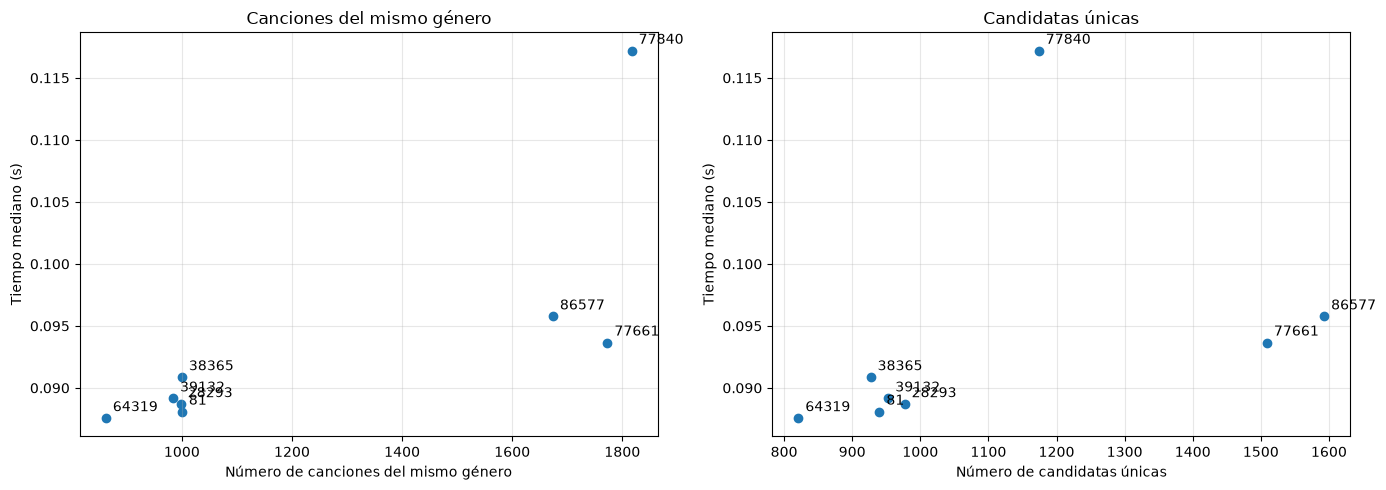

In [33]:
fig, axs = plt.subplots(1, 2, figsize = (14, 5))
g0 = axs[0]
g1 = axs[1]

# Primera gráfica: canciones del mismo género
g0.scatter(df_eficiencia['canciones_mismo_genero'], df_eficiencia['tiempo_mediano'])

for indice, fila in df_eficiencia.iterrows():
    g0.annotate(
        str(indice),
        (fila['canciones_mismo_genero'], fila['tiempo_mediano']),
        xytext = (5, 5),
        textcoords = 'offset points'
    )

g0.set_title('Canciones del mismo género')
g0.set_xlabel('Número de canciones del mismo género')
g0.set_ylabel('Tiempo mediano (s)')
g0.grid(alpha = 0.3)


# Segunda gráfica: candidatas únicas
g1.scatter(df_eficiencia['candidatas_unicas'], df_eficiencia['tiempo_mediano'])

for indice, fila in df_eficiencia.iterrows():
    g1.annotate(
        str(indice),
        (fila['candidatas_unicas'], fila['tiempo_mediano']),
        xytext = (5, 5),
        textcoords = 'offset points'
    )

g1.set_title('Candidatas únicas')
g1.set_xlabel('Número de candidatas únicas')
g1.set_ylabel('Tiempo mediano (s)')
g1.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

In [34]:
# Excluir temporalmente la referencia 86577
df_sin_86577 = df_eficiencia.drop(index=86577)

resultados_sensibilidad = []

for variable in ['canciones_mismo_genero', 'candidatas_unicas']:

    # Correlaciones con las ocho referencias
    pearson_completo = pearsonr(
        df_eficiencia[variable],
        df_eficiencia['tiempo_mediano']
    )[0]

    spearman_completo = spearmanr(
        df_eficiencia[variable],
        df_eficiencia['tiempo_mediano']
    )[0]

    # Correlaciones sin la referencia 86577
    pearson_sin = pearsonr(
        df_sin_86577[variable],
        df_sin_86577['tiempo_mediano']
    )[0]

    spearman_sin = spearmanr(
        df_sin_86577[variable],
        df_sin_86577['tiempo_mediano']
    )[0]

    resultados_sensibilidad.append({
        'variable': variable,
        'pearson_completo': pearson_completo,
        'pearson_sin_86577': pearson_sin,
        'spearman_completo': spearman_completo,
        'spearman_sin_86577': spearman_sin
    })

df_sensibilidad = pd.DataFrame(resultados_sensibilidad)
df_sensibilidad

,variable,pearson_completo,pearson_sin_86577,spearman_completo,spearman_sin_86577
0,canciones_mismo_genero,0.745322,0.782663,0.850315,0.810844
1,candidatas_unicas,0.356879,0.412953,0.761905,0.714286


### **7.8 Comparación entre métodos**

In [35]:
def recomendar_canciones_puro(indice, metodo, n_recomendaciones = 10):
    
    # Validar el índice de referencia
    if indice not in df.index:
        raise ValueError('El índice indicado no existe.')

    # Validar el método
    if metodo not in ['euclidiana', 'coseno']:
        raise ValueError('Método no válido.')

    # Validar el número de recomendaciones
    if not isinstance(n_recomendaciones, int) or isinstance(n_recomendaciones, bool):
        raise TypeError('El número de recomendaciones debe ser un entero.')

    if n_recomendaciones <= 0:
        raise ValueError('El número de recomendaciones debe ser positivo.')

    # Obtener los géneros de la canción de referencia
    generos_referencia = df.loc[indice, 'genres_set']

    # Filtrar canciones que compartan al menos un género
    mascara_genero = df['genres_set'].apply(
        lambda generos: bool(generos_referencia & generos)
    )

    # Excluir la canción de referencia y sus registros equivalentes
    referencia = df.loc[indice]

    misma_cancion = (
        (df['track_name'] == referencia['track_name']) &
        (df['artists'] == referencia['artists'])
    )

    mascara_genero = mascara_genero & ~misma_cancion
    candidatas = df.loc[mascara_genero].copy()

    # Calcular las distancias euclidianas
    caracteristicas_referencia = X_audio_scaled.loc[[indice]]
    X_candidatas = X_audio_scaled.loc[candidatas.index]

    distancias = euclidean_distances(caracteristicas_referencia, X_candidatas).flatten()

    # Incorporar las distancias y eliminar canciones repetidas
    candidatas_unicas = (
        candidatas
        .assign(
            distancia_euclidiana = pd.Series(
                distancias,
                index = candidatas.index
            )
        )
        .sort_values(
            by = 'distancia_euclidiana',
            ascending = True
        )
        .drop_duplicates(
            subset = ['track_name', 'artists'],
            keep = 'first'
        )
    )

    # Calcular la similitud del coseno para todas las candidatas únicas
    X_candidatas_unicas = X_audio_scaled.loc[candidatas_unicas.index]

    similitudes = cosine_similarity(caracteristicas_referencia, X_candidatas_unicas).flatten()

    candidatas_unicas['similitud_coseno'] = similitudes

    # Ordenar según el método seleccionado
    if metodo == 'euclidiana':
        recomendaciones = candidatas_unicas.sort_values(
            by = 'distancia_euclidiana',
            ascending = True
        )

    else:
        recomendaciones = candidatas_unicas.sort_values(
            by = 'similitud_coseno',
            ascending = False
        )

    # Construir la tabla de recomendaciones
    resultado = recomendaciones[
        [
            'track_name',
            'artists',
            'track_genre',
            'album_name',
            'distancia_euclidiana',
            'similitud_coseno'
        ]
    ].head(n_recomendaciones)

    return resultado

In [36]:
recomendaciones_euclidiana = recomendar_canciones_puro(77840, metodo = 'euclidiana')
recomendaciones_coseno = recomendar_canciones_puro(77840, metodo = 'coseno')
recomendaciones_hibridas = recomendar_canciones(77840)

In [37]:
print('Recomendaciones utilizando distancia euclidiana:')
display(recomendaciones_euclidiana)

Recomendaciones utilizando distancia euclidiana:


,track_name,artists,track_genre,album_name,distancia_euclidiana,similitud_coseno
78060,Shower,Becky G,dance;latin;reggae;reggaeton,Shower,0.721647,0.930515
78181,Scared to Be Lonely,Martin Garrix;Dua Lipa,dance;edm;house;progressive-house,Scared to Be Lonely,0.907557,0.865587
14413,Dark Horse,Katy Perry;Juicy J,dance,Halloween 2022,0.979889,0.841791
77981,I Don’t Wanna Live Forever (Fifty Shades Darker),ZAYN;Taylor Swift,dance;pop,reputation Stadium Tour Surprise Song Playlist,1.016902,0.880780
14678,Cool for the Summer - Sped Up (Nightcore),Demi Lovato;Speed Radio,dance,Best Viral Tunes,1.073507,0.805708
87694,The Humma Song,A.R. Rahman;Badshah;Tanishk Bagchi;Shashaa Tir...,pop;pop-film,OK Jaanu (Original Motion Picture Soundtrack),1.080201,0.810927
14555,God is a woman,Ariana Grande,dance,Sweetener,1.159014,0.778478
78069,Real Life,Burna Boy;Stormzy,dance;dancehall;hip-hop,New RnB,1.160020,0.782552
53322,Hold On,Justin Bieber,pop,Autumn Vibes 2022,1.165496,0.782162
81035,idfc,blackbear,electro;pop,dead,1.170133,0.783261


In [38]:
print('Recomendaciones utilizando similitud del coseno:')
display(recomendaciones_coseno)

Recomendaciones utilizando similitud del coseno:


,track_name,artists,track_genre,album_name,distancia_euclidiana,similitud_coseno
78060,Shower,Becky G,dance;latin;reggae;reggaeton,Shower,0.721647,0.930515
77981,I Don’t Wanna Live Forever (Fifty Shades Darker),ZAYN;Taylor Swift,dance;pop,reputation Stadium Tour Surprise Song Playlist,1.016902,0.880780
78181,Scared to Be Lonely,Martin Garrix;Dua Lipa,dance;edm;house;progressive-house,Scared to Be Lonely,0.907557,0.865587
14413,Dark Horse,Katy Perry;Juicy J,dance,Halloween 2022,0.979889,0.841791
53394,Falling,Trevor Daniel,pop,Nicotine,1.188391,0.823348
87694,The Humma Song,A.R. Rahman;Badshah;Tanishk Bagchi;Shashaa Tir...,pop;pop-film,OK Jaanu (Original Motion Picture Soundtrack),1.080201,0.810927
78186,Or Nah - Remix,Ty Dolla $ign;The Weeknd;Wiz Khalifa;DJ Mustard,dance;hip-hop;soul,Good Vibes,1.340376,0.809514
14678,Cool for the Summer - Sped Up (Nightcore),Demi Lovato;Speed Radio,dance,Best Viral Tunes,1.073507,0.805708
78158,Fr Fr,Wiz Khalifa;Lil Skies,dance;hip-hop,Rap Party,1.626549,0.788049
81035,idfc,blackbear,electro;pop,dead,1.170133,0.783261


In [39]:
print('Recomendaciones utilizando el enfoque híbrido:')
display(recomendaciones_hibridas)

Recomendaciones utilizando el enfoque híbrido:


,track_name,artists,track_genre,album_name,distancia_euclidiana,similitud_coseno
78060,Shower,Becky G,dance;latin;reggae;reggaeton,Shower,0.721647,0.930515
77981,I Don’t Wanna Live Forever (Fifty Shades Darker),ZAYN;Taylor Swift,dance;pop,reputation Stadium Tour Surprise Song Playlist,1.016902,0.880780
78181,Scared to Be Lonely,Martin Garrix;Dua Lipa,dance;edm;house;progressive-house,Scared to Be Lonely,0.907557,0.865587
14413,Dark Horse,Katy Perry;Juicy J,dance,Halloween 2022,0.979889,0.841791
53394,Falling,Trevor Daniel,pop,Nicotine,1.188391,0.823348
87694,The Humma Song,A.R. Rahman;Badshah;Tanishk Bagchi;Shashaa Tir...,pop;pop-film,OK Jaanu (Original Motion Picture Soundtrack),1.080201,0.810927
78186,Or Nah - Remix,Ty Dolla $ign;The Weeknd;Wiz Khalifa;DJ Mustard,dance;hip-hop;soul,Good Vibes,1.340376,0.809514
14678,Cool for the Summer - Sped Up (Nightcore),Demi Lovato;Speed Radio,dance,Best Viral Tunes,1.073507,0.805708
78158,Fr Fr,Wiz Khalifa;Lil Skies,dance;hip-hop,Rap Party,1.626549,0.788049
81035,idfc,blackbear,electro;pop,dead,1.170133,0.783261


### **7.8.1 Recomendaciones de las 8 referencias para los 3 métodos**

In [40]:
recomendaciones_metodos = {
    77840: {
        'euclidiana': recomendaciones_euclidiana,
        'coseno': recomendaciones_coseno,
        'hibrido': recomendaciones_hibridas
    }
}

for indice in indices_referencia:
    if indice == 77840:
        continue

    recomendaciones_metodos[indice] = {
        'euclidiana': recomendar_canciones_puro(indice, metodo = 'euclidiana'),
        'coseno': recomendar_canciones_puro(indice, metodo = 'coseno'),
        'hibrido': recomendar_canciones(indice)
    }

In [41]:
import pandas as pd

pares_metodos = [('euclidiana', 'coseno'), ('euclidiana', 'hibrido'), ('coseno', 'hibrido')]

resultados_coincidencias = []
for indice in indices_referencia:

    for metodo_a, metodo_b in pares_metodos:

        # Obtener los índices de las canciones recomendadas
        conjunto_a = set(recomendaciones_metodos[indice][metodo_a].index)

        conjunto_b = set(recomendaciones_metodos[indice][metodo_b].index)

        # Calcular coincidencias y exclusivas
        comunes = conjunto_a & conjunto_b
        exclusivas_a = conjunto_a - conjunto_b
        exclusivas_b = conjunto_b - conjunto_a

        # Calcular el índice de Jaccard
        jaccard = len(comunes) / len(conjunto_a | conjunto_b)

        resultados_coincidencias.append({
            'indice_referencia': indice,
            'metodo_a': metodo_a,
            'metodo_b': metodo_b,
            'coincidencias': len(comunes),
            'exclusivas_a': len(exclusivas_a),
            'exclusivas_b': len(exclusivas_b),
            'jaccard': jaccard
        })

df_coincidencias = pd.DataFrame(resultados_coincidencias)
df_coincidencias

,indice_referencia,metodo_a,metodo_b,coincidencias,exclusivas_a,exclusivas_b,jaccard
0,77840,euclidiana,coseno,7,3,3,0.538462
1,77840,euclidiana,hibrido,7,3,3,0.538462
2,77840,coseno,hibrido,10,0,0,1.000000
3,86577,euclidiana,coseno,7,3,3,0.538462
4,86577,euclidiana,hibrido,7,3,3,0.538462
5,86577,coseno,hibrido,10,0,0,1.000000
6,39132,euclidiana,coseno,8,2,2,0.666667
7,39132,euclidiana,hibrido,8,2,2,0.666667
8,39132,coseno,hibrido,10,0,0,1.000000
9,38365,euclidiana,coseno,8,2,2,0.666667


### **7.8.2 Equivalencia entre el método híbrido y el del coseno**

In [42]:
for indice in indices_referencia:

    coseno = recomendaciones_metodos[indice]['coseno']
    hibrido = recomendaciones_metodos[indice]['hibrido']

    mismas_canciones = coseno.index.equals(hibrido.index)

    mismos_valores = (coseno['similitud_coseno'].equals(hibrido['similitud_coseno']))

    print(
        f'{indice}: '
        f'Canciones y orden = {mismas_canciones}, '
        f'Valores de coseno = {mismos_valores}'
    )

77840: Canciones y orden = True, Valores de coseno = True
86577: Canciones y orden = True, Valores de coseno = True
39132: Canciones y orden = True, Valores de coseno = True
38365: Canciones y orden = True, Valores de coseno = True
28293: Canciones y orden = True, Valores de coseno = True
77661: Canciones y orden = True, Valores de coseno = True
81: Canciones y orden = True, Valores de coseno = True
64319: Canciones y orden = True, Valores de coseno = True


### **7.8.3 Diversidad acústica**

In [43]:
resultados_diversidad = []

for indice in indices_referencia:

    for metodo in ['euclidiana', 'hibrido']:

        # Obtener las recomendaciones del método
        recomendaciones = recomendaciones_metodos[indice][metodo]

        # Recuperar sus características acústicas escaladas
        vectores = X_audio_scaled.loc[recomendaciones.index]

        # Calcular las distancias entre todos los pares
        matriz_distancias = pairwise_distances(vectores, metric = 'euclidean')

        # Extraer únicamente las distancias entre pares distintos
        indices_pares = np.triu_indices(len(vectores), k = 1)
        distancias_pares = matriz_distancias[indices_pares]

        # Calcular la distancia promedio
        distancia_promedio = distancias_pares.mean()

        resultados_diversidad.append({
            'indice_referencia': indice,
            'metodo': metodo,
            'diversidad_acustica': distancia_promedio
        })

df_diversidad_comparacion = pd.DataFrame(resultados_diversidad)
df_diversidad_comparacion

,indice_referencia,metodo,diversidad_acustica
0,77840,euclidiana,1.250666
1,77840,hibrido,1.531698
2,86577,euclidiana,0.689221
3,86577,hibrido,0.696965
4,39132,euclidiana,0.997811
5,39132,hibrido,0.941790
6,38365,euclidiana,0.841152
7,38365,hibrido,0.995145
8,28293,euclidiana,0.744023
9,28293,hibrido,0.744023


In [44]:
tabla_diversidad = df_diversidad_comparacion.pivot(
    index = 'indice_referencia',
    columns = 'metodo',
    values = 'diversidad_acustica'
)

tabla_diversidad['diferencia'] = (tabla_diversidad['hibrido'] - tabla_diversidad['euclidiana'])
tabla_diversidad

metodo,euclidiana,hibrido,diferencia
indice_referencia,,,
81,1.342399,1.475008,1.326087e-01
28293,0.744023,0.744023,1.110223e-16
38365,0.841152,0.995145,1.539935e-01
39132,0.997811,0.941790,-5.602119e-02
64319,0.634958,0.746010,1.110521e-01
77661,1.135618,1.120054,-1.556427e-02
77840,1.250666,1.531698,2.810326e-01
86577,0.689221,0.696965,7.744112e-03


### **7.8.4 Divsersidad de géneros**

In [45]:
resultados_generos = []

for indice in indices_referencia:

    for metodo in ['euclidiana', 'hibrido']:

        # Obtener las recomendaciones
        recomendaciones = recomendaciones_metodos[indice][metodo]

        # Recuperar los géneros de cada canción
        generos = df.loc[recomendaciones.index, 'genres_set']

        # Separar los géneros y contar sus frecuencias
        frecuencias = (generos.explode().value_counts())

        # Guardar los resultados
        for genero, frecuencia in frecuencias.items():

            resultados_generos.append({
                'indice_referencia': indice,
                'metodo': metodo,
                'genero': genero,
                'frecuencia': frecuencia
            })

df_generos_comparacion = pd.DataFrame(resultados_generos)
df_generos_comparacion

,indice_referencia,metodo,genero,frecuencia
0,77840,euclidiana,dance,7
1,77840,euclidiana,pop,4
2,77840,euclidiana,reggaeton,1
3,77840,euclidiana,latin,1
4,77840,euclidiana,reggae,1
5,77840,euclidiana,house,1
6,77840,euclidiana,progressive-house,1
7,77840,euclidiana,edm,1
8,77840,euclidiana,pop-film,1
9,77840,euclidiana,hip-hop,1


In [46]:
tabla_num_generos = (
    df_generos_comparacion
    .groupby(['indice_referencia', 'metodo'])['genero']
    .nunique()
    .unstack()
)

tabla_num_generos['diferencia'] = (tabla_num_generos['hibrido'] - tabla_num_generos['euclidiana'])
tabla_num_generos

metodo,euclidiana,hibrido,diferencia
indice_referencia,,,
81,3,3,0
28293,1,1,0
38365,1,4,3
39132,1,1,0
64319,1,1,0
77661,3,3,0
77840,12,12,0
86577,4,2,-2


In [47]:
resultados_entropia = []

for (indice, metodo), grupo in df_generos_comparacion.groupby(['indice_referencia', 'metodo']):

    # Frecuencias relativas de los géneros
    frecuencias = grupo['frecuencia'].to_numpy()
    probabilidades = frecuencias / frecuencias.sum()

    # Número de géneros distintos
    n_generos = len(frecuencias)

    # Entropía de Shannon
    entropia = -np.sum(probabilidades * np.log(probabilidades))

    # Entropía normalizada
    entropia_normalizada = (
        entropia / np.log(n_generos)
        if n_generos > 1
        else 0
    )

    resultados_entropia.append({
        'indice_referencia': indice,
        'metodo': metodo,
        'entropia': entropia,
        'entropia_normalizada': entropia_normalizada
    })

df_entropia_comparacion = pd.DataFrame(resultados_entropia)
df_entropia_comparacion

,indice_referencia,metodo,entropia,entropia_normalizada
0,81,euclidiana,0.566086,0.515273
1,81,hibrido,0.566086,0.515273
2,28293,euclidiana,-0.000000,0.000000
3,28293,hibrido,-0.000000,0.000000
4,38365,euclidiana,-0.000000,0.000000
5,38365,hibrido,0.793730,0.572555
6,39132,euclidiana,-0.000000,0.000000
7,39132,hibrido,-0.000000,0.000000
8,64319,euclidiana,-0.000000,0.000000
9,64319,hibrido,-0.000000,0.000000


In [48]:
tabla_entropia = df_entropia_comparacion.pivot(
    index = 'indice_referencia',
    columns = 'metodo',
    values = 'entropia_normalizada'
)

tabla_entropia['diferencia'] = (tabla_entropia['hibrido'] - tabla_entropia['euclidiana'])
tabla_entropia

metodo,euclidiana,hibrido,diferencia
indice_referencia,,,
81,0.515273,0.515273,0.000000
28293,0.000000,0.000000,0.000000
38365,0.000000,0.572555,0.572555
39132,0.000000,0.000000,0.000000
64319,0.000000,0.000000,0.000000
77661,0.755928,0.690814,-0.065114
77840,0.857911,0.867969,0.010058
86577,0.771782,0.995727,0.223945


### **7.8.5 Distribución de popularidad**

In [49]:
categorias = ['sin popularidad', 'baja', 'media', 'alta']

resultados_popularidad = []

for indice in indices_referencia:
    for metodo in ['euclidiana', 'hibrido']:

        recomendaciones = recomendaciones_metodos[indice][metodo]
        popularidad = df.loc[recomendaciones.index, 'popularity']

        condiciones = [
            popularidad == 0,
            popularidad.between(1, 26),
            popularidad.between(27, 45),
            popularidad.between(46, 100)
        ]

        clasificacion = np.select(condiciones, categorias, default = 'sin clasificar')

        frecuencias = pd.Series(
            clasificacion
        ).value_counts().reindex(categorias, fill_value = 0)

        for categoria, frecuencia in frecuencias.items():
            resultados_popularidad.append({
                'indice_referencia': indice,
                'metodo': metodo,
                'categoria': categoria,
                'frecuencia': frecuencia
            })

df_popularidad_comparacion = pd.DataFrame(resultados_popularidad)

In [50]:
tabla_popularidad = df_popularidad_comparacion.pivot(
    index = 'indice_referencia',
    columns = ['metodo', 'categoria'],
    values = 'frecuencia'
)

tabla_popularidad

metodo                 euclidiana                         hibrido             \
categoria         sin popularidad baja media alta sin popularidad baja media   
indice_referencia                                                              
81                              1    1     2    6               1    1     2   
28293                           0   10     0    0               0   10     0   
38365                           0    6     1    3               0    8     0   
39132                           4    6     0    0               4    6     0   
64319                           0    0     2    8               0    0     2   
77661                           6    4     0    0               5    5     0   
77840                           4    0     0    6               3    1     0   
86577                           1    2     4    3               0    2     4   

metodo                  
categoria         alta  
indice_referencia       
81                   6  
28293                0  
38365                2  
39132                0  
64319                8  
77661                0  
77840                6  
86577                4